# Does weaker acid change what survives? Test one small peptide at two acid strengths

You'll pick one small peptide and decide whether it survives in 98% and in 81% sulfuric acid.

The study behind notebook 01 tested all 20 homodipeptides (two copies of one amino acid joined,
such as Ala-Ala) in both acids. Once reviewed, your verdict goes into the community replication
table.

| Part | What you do | Time |
|---|---|---|
| 0 | Pick a dipeptide and predict | 10 min |
| 1 | Stack both series and check them | 20 min |
| 2 | Compare first and last in each acid | 25 min |
| 3 | Record your verdict | 10 min |
| 4 | Check your verdict against the paper | 5 min |

There is no worked example for your molecule. You run the full analysis yourself, and Gly-Gly
from notebook 01 sits next to your answers as a filled example. Boxes headed **RECORD YOUR
ANSWER** are where you write something. Being wrong or unsure is fine: you compare with the
paper's tables at the end.

Data: Petkowski, M. D. Seager, Bains and S. Seager, Zenodo [10.5281/zenodo.11223995](https://doi.org/10.5281/zenodo.11223995), CC BY 4.0. Paper: *Scientific Reports* 14, 17083 (2024).

In [1]:
# Setup. In Colab this first installs the training package (about 30 seconds).
import importlib.util, os
if importlib.util.find_spec("nmrtrain") is None:
    %pip install -q "nmrtrain @ git+https://github.com/Rakiura-Inc/morning-star-nmr@main"
import matplotlib.pyplot as plt
import nmrtrain as nt

NOTEBOOK = "notebooks/02_one_dipeptide_both_acids.ipynb"
MODE = nt.portal.connect(NOTEBOOK)

Offline mode: progress is kept in handin/rakiura_progress.json.


## Part 0: Pick and predict

In [2]:
for code_ in nt.data.samples("11223995"):
    print(code_, nt.io.NAMES[code_])

AA Ala-Ala
CC Cys-Cys
DD Asp-Asp
EE Glu-Glu
FF Phe-Phe
GG Gly-Gly
HH His-His
II Ile-Ile
KK Lys-Lys
LL Leu-Leu
MM Met-Met
NN Asn-Asn
PP Pro-Pro
QQ Gln-Gln
RR Arg-Arg
SS Ser-Ser
TT Thr-Thr
VV Val-Val
WW Trp-Trp
YY Tyr-Tyr


### What you need

You know two calls in 98% acid from notebook 01: Ala-Ala breaks down and Gly-Gly survives. Most
dipeptides break apart in this acid (bootcamp step 2). The 81% acid is the same acid with more
water in it (81% acid by weight, the rest heavy water). Your prediction is a guess with a reason;
the spectra settle it.

Longer version: NMR project step 1, Does weaker acid change what survives? Test one small peptide at two acid strengths.

> **RECORD YOUR ANSWER: pick a dipeptide and predict what the two acids do to it**
>
> **What gets saved:** `DIPEPTIDE`, the code you picked, and `MY_PREDICTION`, three short answers, saved with the time.
>
> **Where to look:** the list of codes above, and what you found in notebook 01.
>
> **How to fill this in:**
> - `DIPEPTIDE`: a two-letter code from the list, in quotes, like `"LL"`, or the one your mentor assigned
> - `"K"` (98% acid): `"survives"`, `"breaks down"` or `"unsure"`
> - `"H"` (81% acid): the same choices
> - `"harsher"`: which acid you expect to be harsher on it: `"98%"`, `"81%"`, `"same"` or `"unsure"`

<details><summary>Stuck? Open hint 1</summary>

Nothing in the structure alone settles this. Write a guess with a reason, and "unsure" where
you have no basis.

</details>

<details><summary>Stuck? Open hint 2</summary>

Two things pull in different directions: 98% acid is the stronger acid, but 81% acid holds more
water, and water is what splits a peptide bond on Earth. Pick the one you think wins for your
dipeptide.

</details>

In [3]:
DIPEPTIDE = "LL"   # change this to the two-letter code of the dipeptide you picked

MY_PREDICTION = {
    "K": ...,          # 98% acid: "survives", "breaks down" or "unsure"
    "H": ...,          # 81% acid: "survives", "breaks down" or "unsure"
    "harsher": ...,    # which acid is harsher on it: "98%", "81%", "same" or "unsure"
}
nt.record.predict("dipeptide", MY_PREDICTION)

Fill in at least one prediction above (replace the ...), then run this cell again.


## Part 1: Load and stack

Acid code `K` is 98% and `H` is 81%. The next cell downloads both series (about 5 MB) and prints
where the acid peak sits in each spectrum.

In [4]:
series = {acid: nt.load_series("11223995", DIPEPTIDE, acid=acid, nucleus="1H") for acid in "KH"}
for acid, ser in series.items():
    print(acid, [s.time_label for s in ser], "| acid peak at", [round(nt.checks.acid_ppm(s), 2) for s in ser])

LL 1H 98% w/w D2SO4: 5 spectra, all cached
Data: Petkowski, J. J.; Seager, M. D.; Bains, W.; Seager, S. (2024). General Instability of Dipeptides in Concentrated Sulfuric Acid as Relevant for the Venus Cloud Habitability (Supplementary dataset S1). Zenodo. https://doi.org/10.5281/zenodo.11223995 (CC BY 4.0). Paper: Petkowski et al. 2024, Scientific Reports 14, 17083, doi:10.1038/s41598-024-67342-w.
LL 1H 81% w/w D2SO4: 5 spectra, all cached
Data: Petkowski, J. J.; Seager, M. D.; Bains, W.; Seager, S. (2024). General Instability of Dipeptides in Concentrated Sulfuric Acid as Relevant for the Venus Cloud Habitability (Supplementary dataset S1). Zenodo. https://doi.org/10.5281/zenodo.11223995 (CC BY 4.0). Paper: Petkowski et al. 2024, Scientific Reports 14, 17083, doi:10.1038/s41598-024-67342-w.
K ['1 day', '3 days', '8 days', '5 weeks', '4 months'] | acid peak at [11.46, 11.47, 11.47, 11.48, 11.5]
H ['1 day', '3 days', '8 days', '5 weeks', '4 months'] | acid peak at [11.98, 11.98, 11.98,

In 81% acid the acid peak sits higher (about 11.7 to 12.1 ppm), and your molecule's peaks sit at
different ppm than in 98%. Compare each acid's series only with itself, never across acids.

### What you need

`REGION` is the ppm range you plot and read. The hydrogens on carbon of most dipeptides sit
between 1 and 6.5 ppm. Hydrogens on an aromatic ring (a flat ring, in Phe-Phe, Tyr-Tyr, Trp-Trp
and His-His) sit between 6.5 and 9 ppm. Leave out the acid peak (11.4 to 12.1 ppm).

Longer version: NMR project step 1, Does weaker acid change what survives? Test one small peptide at two acid strengths.

> **RECORD YOUR ANSWER: choose the ppm range to read**
>
> **What gets saved:** `REGION`, two numbers in ppm in round brackets, low then high.
>
> **Where to look:** the name of your dipeptide in the list above: does its side chain have an aromatic ring?
>
> **How to fill this in:**
> - No aromatic ring: `(1.0, 6.5)`. Aromatic ring: `(0.5, 9.5)`.
> - Left as `...`, the cell uses `(0.5, 9.5)`.

<details><summary>Stuck? Open hint 1</summary>

Look up your dipeptide's amino acid: is it Phe, Tyr, Trp or His?

</details>

<details><summary>Stuck? Open hint 2</summary>

Phe, Tyr, Trp and His have aromatic rings. Proline's ring is not aromatic, so Pro-Pro uses `(1.0, 6.5)`.

</details>

To do: REGION is not filled in yet, so the notebook uses (0.5, 9.5) for now.


**Saved** `REGION = (0.5, 9.5)`: the ppm range you read.

Checks on Leu-Leu in 98% acid: 10 passed, 0 flagged
  nothing to flag
Checks on Leu-Leu in 81% acid: 10 passed, 0 flagged
  nothing to flag


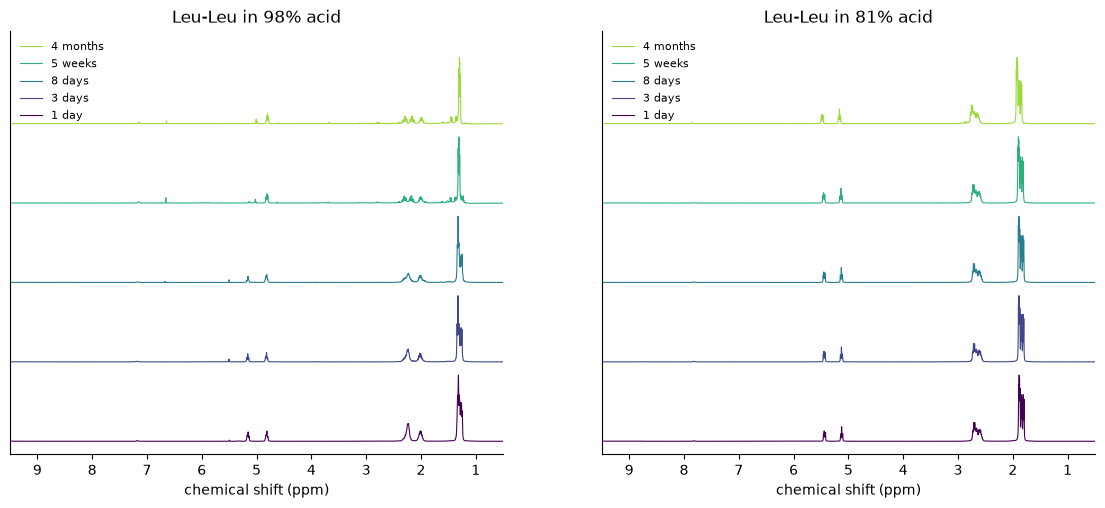

Stacked plot saved (offline mode: kept on this computer).


In [5]:
REGION = ...   # two numbers in ppm, low then high, like (1.0, 6.5) or (0.5, 9.5)
REGION = nt.record.fill(REGION, (0.5, 9.5), "REGION")
nt.record.saved("REGION", REGION, "the ppm range you read")

fig_stacks, axes = plt.subplots(1, 2, figsize=(14, 5.5))
traps = {}
for ax, (acid, ser) in zip(axes, series.items()):
    nt.plot.stack(ser, REGION[0], REGION[1], norm=REGION, ax=ax,
                  title=f"{nt.io.NAMES[DIPEPTIDE]} in {nt.io.ACID_PCT[acid]} acid")
    traps[acid] = nt.checks.run_traps(ser, norm=REGION, lo=REGION[0], hi=REGION[1])
plt.show()
nt.portal.done("dipeptide-stack", figures=[fig_stacks]);

## Part 2: First vs last, in each acid

In some samples the whole spectrum moves a little between the first and last time points,
especially in 81% acid. A peak that moved by the same amount as all the others is the same peak.
The next cell lists the peaks kept, lost and new in each acid.

98%: at both times 4.81, 2.01, 1.29 | first only 5.16, 2.23 | last only 6.64, 5.01, 2.29, 2.16, 1.60, 1.45, 1.36
81%: at both times 5.44, 5.12, 2.70, 2.66, 2.60, 1.86 | first only none | last only none


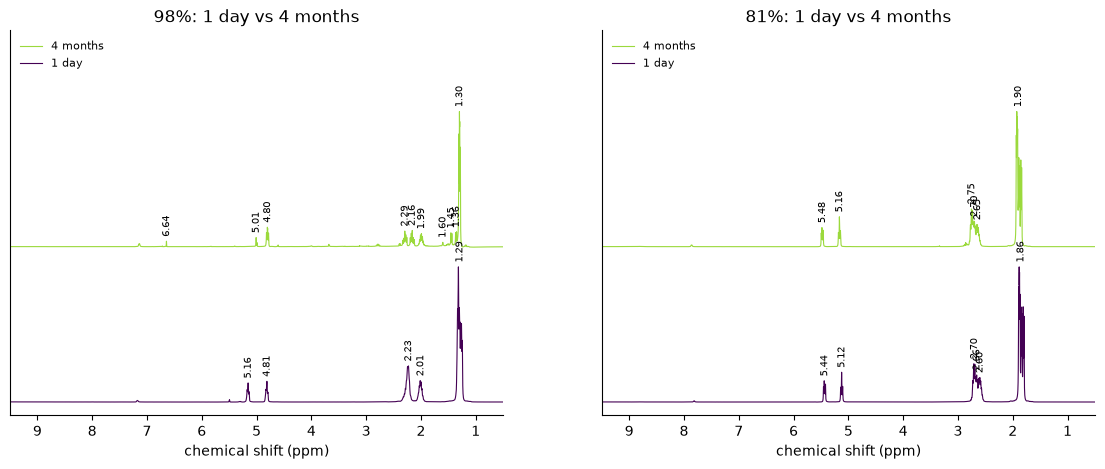

In [6]:
MIN_HEIGHT = 0.03
my_peaks, changes, fig_cmp = {}, {}, plt.figure(figsize=(14, 5))
for i, (acid, ser) in enumerate(series.items()):
    first, last = ser[0], ser[-1]
    my_peaks[acid] = {first.time: nt.peaks.pick(first, *REGION, MIN_HEIGHT),
                      last.time: nt.peaks.pick(last, *REGION, MIN_HEIGHT)}
    changes[acid] = nt.peaks.compare(*my_peaks[acid].values())
    ax = fig_cmp.add_subplot(1, 2, i + 1)
    nt.plot.compare(first, last, *REGION, peaks_first=my_peaks[acid][first.time],
                    peaks_last=my_peaks[acid][last.time], ax=ax,
                    title=f"{nt.io.ACID_PCT[acid]}: {first.time_label} vs {last.time_label}")
    c = {k: ", ".join(f"{p:.2f}" for p in v) or "none" for k, v in changes[acid].items()}
    print(f"{nt.io.ACID_PCT[acid]}: at both times {c['kept']} | first only {c['lost']} | last only {c['new']}")
plt.show()

### How much is left

In hydrogen NMR the area under a signal is proportional to the number of hydrogens. These samples
have no added reference compound, so compare within one spectrum: one of your dipeptide's signals
as a share of all the area from hydrogens on carbon in `REGION`. The next cell follows the tallest
signal at the first time point; set `SIGNAL_PPM` to follow another one. Pick a signal that belongs
only to the intact dipeptide, such as one the picker lists at the first time only: a signal shared
with a product can stay high while the dipeptide goes.

In [7]:
SIGNAL_PPM = None   # optional: the ppm of the signal to follow, like 1.41; None follows the tallest
skip = None if DIPEPTIDE in nt.checks.AROMATIC else nt.checks.EXCHANGEABLE   # leave out NH signals
for acid, ser in series.items():
    center = SIGNAL_PPM or nt.peaks.tallest_ppm(ser[0], *REGION)
    window = (center - 0.05, center + 0.05)
    shares = ", ".join(f"{s.time_label} {nt.peaks.share(s, window, REGION, skip):.0%}" for s in ser)
    print(f"{nt.io.ACID_PCT[acid]}: signal near {center:.2f} ppm, share of the area from hydrogens on carbon: {shares}")

98%: signal near 1.32 ppm, share of the area from hydrogens on carbon: 1 day 45%, 3 days 48%, 8 days 47%, 5 weeks 45%, 4 months 47%
81%: signal near 1.88 ppm, share of the area from hydrogens on carbon: 1 day 39%, 3 days 41%, 8 days 42%, 5 weeks 44%, 4 months 49%


### A filled example: Gly-Gly in 98% acid

Gly-Gly from notebook 01, filled in with the reasons. It shows the format; your dipeptide's values
will differ.

In [8]:
GG_EXAMPLE = {
    "call": "survives",          # both CH2 signals are still there, in the same place, at 4 months
    "lost_ppm": [],              # nothing from day 1 is gone
    "new_ppm": [4.33],           # one tiny peak at 4 months, far smaller than the two main signals
    "kept_ppm": [4.77, 4.61],    # the two CH2 signals, one per glycine
    "left": "most",              # the two CH2 signals still hold most of the area from hydrogens on carbon
    "product_guess": "none",
    "confidence": "high",
    "note": "notebook 01, for comparison",
}

### What you need

- **Lost:** a peak at the first time point that is gone, or much smaller, at the last.
- **New:** a peak at the last time point that was not there at the first.
- **Kept:** a peak at both times. A peak that moved by the same amount as all the others is the same
  peak.
- **How much is left:** from the shares printed above: most, about half, or little or none.
- NH signals often fade by exchange with the acid's deuterium; that alone is not breakdown.

Longer version: NMR project step 1, Does weaker acid change what survives? Test one small peptide at two acid strengths.

> **RECORD YOUR ANSWER: what changed in each acid?**
>
> **What gets saved:** `K_LOST_PPM`, `K_NEW_PPM`, `K_KEPT_PPM` and `K_LEFT` for 98% acid, and the same four starting `H_` for 81% acid.
>
> **Where to look:** the two first-vs-last plots above (98% on the left, 81% on the right), the lists printed under them, and the shares under How much is left.
>
> **How to fill this in:**
> - `..._LOST_PPM`: peaks there at the first time point and gone or much smaller at the last, as numbers like `[1.23, 4.56]`
> - `..._NEW_PPM`: peaks at the last time point that were not there at the first
> - `..._KEPT_PPM`: peaks there at both times
> - `..._LEFT`: `"most"`, `"about half"`, `"little or none"` or `"unsure"`
> - Leave a list as `[]` if there were none. Gly-Gly's record above shows the format.

<details><summary>Stuck? Open hint 1</summary>

Read one acid at a time, one peak at a time: for each first-time peak, is there still a peak in the same place at the last time point?

</details>

<details><summary>Stuck? Open hint 2</summary>

In 81% acid the whole spectrum can move a little between time points. If every peak moved by
about the same amount, count them as kept.

</details>

In [9]:
K_LOST_PPM = []    # 98% acid: peaks there at the first time point and gone or much smaller at the last
K_NEW_PPM = []     # 98% acid: peaks at the last time point that were not there at the first
K_KEPT_PPM = []    # 98% acid: peaks there at both times
K_LEFT = ""        # 98% acid: "most", "about half", "little or none" or "unsure"
H_LOST_PPM = []    # 81% acid: the same four
H_NEW_PPM = []
H_KEPT_PPM = []
H_LEFT = ""

name = nt.io.NAMES[DIPEPTIDE]
for acid, (lost, new, kept, left) in {"K": (K_LOST_PPM, K_NEW_PPM, K_KEPT_PPM, K_LEFT),
                                      "H": (H_LOST_PPM, H_NEW_PPM, H_KEPT_PPM, H_LEFT)}.items():
    who = f"{name} in {nt.io.ACID_PCT[acid]} acid"
    nt.record.write_down(f"{acid}_LOST_PPM", lost, who, "lost_ppm", suggestion=changes[acid]["lost"])
    nt.record.write_down(f"{acid}_NEW_PPM", new, who, "new_ppm", suggestion=changes[acid]["new"])
    nt.record.write_down(f"{acid}_KEPT_PPM", kept, who, "kept_ppm", suggestion=changes[acid]["kept"])
    nt.record.write_down(f"{acid}_LEFT", left, who, "left")

**Saved** `K_LOST_PPM = []`: no lost peaks for Leu-Leu in 98% acid. If there were none, that is your answer and you can move on. The peak picker listed these as lost: 5.16 and 2.23. Copy the ones you agree with.

**Saved** `K_NEW_PPM = []`: no new peaks for Leu-Leu in 98% acid. If there were none, that is your answer and you can move on. The peak picker listed these as new: 6.64, 5.01, 2.29, 2.16, 1.6, 1.45 and 1.36. Copy the ones you agree with.

**Saved** `K_KEPT_PPM = []`: no kept peaks for Leu-Leu in 98% acid. If there were none, that is your answer and you can move on. The peak picker listed these as kept: 4.81, 2.01 and 1.29. Copy the ones you agree with.

**Not saved yet** `K_LEFT = ''`: write how much is left for Leu-Leu in 98% acid: one of "most", "about half", "little or none" or "unsure" ("unsure" is a fair answer).

**Saved** `H_LOST_PPM = []`: no lost peaks for Leu-Leu in 81% acid. If there were none, that is your answer and you can move on.

**Saved** `H_NEW_PPM = []`: no new peaks for Leu-Leu in 81% acid. If there were none, that is your answer and you can move on.

**Saved** `H_KEPT_PPM = []`: no kept peaks for Leu-Leu in 81% acid. If there were none, that is your answer and you can move on. The peak picker listed these as kept: 5.44, 5.12, 2.7, 2.66, 2.6 and 1.86. Copy the ones you agree with.

**Not saved yet** `H_LEFT = ''`: write how much is left for Leu-Leu in 81% acid: one of "most", "about half", "little or none" or "unsure" ("unsure" is a fair answer).

## Part 3: Your verdict

### What you need

A dipeptide that survives keeps every signal from hydrogens on carbon in place. One that breaks
down loses signals, and new ones appear. A side chain change keeps the backbone signals and adds new
ones beside them. If it broke down, the pieces are its two amino acids or close relatives of them.

Longer version: NMR project step 1, Does weaker acid change what survives? Test one small peptide at two acid strengths.

> **RECORD YOUR ANSWER: your call in each acid**
>
> **What gets saved:** `K_CALL`, `H_CALL`, `K_PRODUCT`, `H_PRODUCT`, `K_CONFIDENCE`, `H_CONFIDENCE`, `HARSHER` and `NOTE`.
>
> **Where to look:** the lost, new and kept peaks you saved above.
>
> **How to fill this in:**
> - `..._CALL`: `"survives"`, `"breaks down"`, `"side chain changed"` or `"unsure"` (unsure is a good answer when the data do not settle it)
> - `..._PRODUCT`: the main product in words, `"none"`, or `""` if you have no idea yet
> - `..._CONFIDENCE`: `"low"`, `"medium"` or `"high"`
> - `HARSHER`: the acid that was harsher on it: `"98%"`, `"81%"`, `"same"` or `"unsure"`
> - `NOTE`: anything you want your reviewer to know, or `""`

<details><summary>Stuck? Open hint 1</summary>

Which acid lost more of its first-time peaks, and which kept more of its area?

</details>

<details><summary>Stuck? Open hint 2</summary>

If one acid shows little or none left and the other most, the first was harsher. If both look
the same, write "same".

</details>

In [10]:
K_CALL = ""          # 98%: "survives", "breaks down", "side chain changed" or "unsure"
H_CALL = ""          # 81%: the same choices
K_PRODUCT = ""       # 98%: the main product in words, "none", or "" if no idea yet
H_PRODUCT = ""       # 81%: the same
K_CONFIDENCE = ""    # 98%: "low", "medium" or "high"
H_CONFIDENCE = ""    # 81%: "low", "medium" or "high"
HARSHER = ""         # "98%", "81%", "same" or "unsure"
NOTE = ""            # anything you want your reviewer to know

for acid, (call, product, conf) in {"K": (K_CALL, K_PRODUCT, K_CONFIDENCE), "H": (H_CALL, H_PRODUCT, H_CONFIDENCE)}.items():
    who = f"{name} in {nt.io.ACID_PCT[acid]} acid"
    nt.record.write_down(f"{acid}_CALL", call, who, "call")
    nt.record.write_down(f"{acid}_PRODUCT", product, who, "product_guess")
    nt.record.write_down(f"{acid}_CONFIDENCE", conf, who, "confidence")
nt.record.write_down("HARSHER", HARSHER, name, "harsher")
nt.record.write_down("NOTE", NOTE, name, "note");

**Not saved yet** `K_CALL = ''`: write the call for Leu-Leu in 98% acid: one of "survives", "breaks down", "side chain changed" or "unsure" ("unsure" is a fair answer).

**Not saved yet** `K_PRODUCT = ''`: write what you think Leu-Leu in 98% acid turned into, "none" if nothing new formed, or leave "" if you have no idea yet.

**Not saved yet** `K_CONFIDENCE = ''`: write the confidence for Leu-Leu in 98% acid: one of "low", "medium" or "high".

**Not saved yet** `H_CALL = ''`: write the call for Leu-Leu in 81% acid: one of "survives", "breaks down", "side chain changed" or "unsure" ("unsure" is a fair answer).

**Not saved yet** `H_PRODUCT = ''`: write what you think Leu-Leu in 81% acid turned into, "none" if nothing new formed, or leave "" if you have no idea yet.

**Not saved yet** `H_CONFIDENCE = ''`: write the confidence for Leu-Leu in 81% acid: one of "low", "medium" or "high".

**Not saved yet** `HARSHER = ''`: write which acid was harsher for Leu-Leu: one of "98%", "81%", "same" or "unsure" ("unsure" is a fair answer).

**Saved** `NOTE = ''`: no note for Leu-Leu. That is fine.

### Your verdict

Here is your verdict, built from what you recorded above. Change any line above and re-run this
cell to update it. The Gly-Gly row is the filled example from notebook 01.

In [11]:
MY_VERDICT = nt.record.build_verdict(
    {"K": {"call": K_CALL, "lost_ppm": K_LOST_PPM, "new_ppm": K_NEW_PPM, "kept_ppm": K_KEPT_PPM, "left": K_LEFT,
           "product_guess": K_PRODUCT, "confidence": K_CONFIDENCE},
     "H": {"call": H_CALL, "lost_ppm": H_LOST_PPM, "new_ppm": H_NEW_PPM, "kept_ppm": H_KEPT_PPM, "left": H_LEFT,
           "product_guess": H_PRODUCT, "confidence": H_CONFIDENCE}},
    names={"K": f"{name}, 98%", "H": f"{name}, 81%"},
    examples={"Gly-Gly, 98% (example)": GG_EXAMPLE},
    harsher=HARSHER, note=NOTE)

| | call | lost peaks (ppm) | new peaks (ppm) | kept peaks (ppm) | how much is left | product guess | confidence | note |
|---|---|---|---|---|---|---|---|---|
| **Gly-Gly, 98% (example)** | survives | none | 4.33 | 4.77, 4.61 | most | none | high | notebook 01, for comparison |
| **Leu-Leu, 98%** | (empty) | none | none | none | (empty) | (empty) | (empty) | (empty) |
| **Leu-Leu, 81%** | (empty) | none | none | none | (empty) | (empty) | (empty) | (empty) |

  Leu-Leu, 98%: still empty: call, lost peaks, new peaks, kept peaks, how much is left, product guess, confidence. An empty peak list is fine if there were none, and "unsure" is a fair call.
  Leu-Leu, 81%: still empty: call, lost peaks, new peaks, kept peaks, how much is left, product guess, confidence. An empty peak list is fine if there were none, and "unsure" is a fair call.
Nothing here blocks your hand-in. Change any answer above and run the cells again to update it.


## Part 4: Check your verdict against the paper

The paper states a call outright for Ala-Ala and Gly-Gly in 98% acid, and the next cell compares
your call with those. For any other case, check your call against Table 1 (81%) and Table 2 (98%)
of the paper (Petkowski et al. 2024, *Scientific Reports* 14, 17083), and say in your `NOTE` what
you found. If your call differs from the paper's, look again at the peaks you listed; your hand-in
goes to review as you wrote it.

In [12]:
feedback, matches = {}, {}
if nt.record.revealed("dipeptide"):
    key = nt.answers.load("dipeptides")
    for acid in "KH":
        c = nt.answers.case(key, f"{DIPEPTIDE}-{acid}")
        feedback[acid] = nt.checks.check_verdict(MY_VERDICT[acid], c).show(f"Your verdict, {nt.io.ACID_PCT[acid]} acid")
        call = nt.checks.plain_call(MY_VERDICT[acid]["call"])
        matches[acid] = ("unsure" if not c.get("call") or call in ("", "unsure")
                         else ("yes" if call == nt.checks.plain_call(c["call"]) else "no"))

Make your prediction in the cell above first.


## Hand-in

> **SAVE YOUR HAND-IN: your dipeptide hand-in**
>
> **What gets saved:** in `handin/`: the stacks for both acids, the first vs last comparison, `verdict.json` (your verdict table, peak lists and feedback) and `replication_rows.csv` (your two lines for the replication table, one per acid).
>
> **Where to look:** nothing new to fill in: the cell uses what you recorded above.
>
> **How to fill this in:**
> - Run the cell. Nothing is sent for review until you run `nt.portal.submit()`.

<details><summary>Stuck? Open hint 1</summary>

If a figure is missing from the list it prints, run the cell that draws it, then this cell again.

</details>

<details><summary>Stuck? Open hint 2</summary>

If it says a name is not defined, run the notebook from the top (Runtime > Run all in Colab).

</details>

In [13]:
n_traps = nt.checks.traps_flagged(*traps.values())
record = nt.record.handin(
    "dipeptide-verdict", figures={"stacks": fig_stacks, "first_vs_last": fig_cmp},
    verdict={"dipeptide": DIPEPTIDE, "verdict": MY_VERDICT,
             "my_peaks_ppm": {a: {t: nt.peaks.ppms(v) for t, v in d.items()} for a, d in my_peaks.items()},
             "feedback": {a: [str(f) for f in v] for a, v in feedback.items()}},
    numbers={"sample": DIPEPTIDE, "call_98": MY_VERDICT["K"]["call"] or "blank",
             "call_81": MY_VERDICT["H"]["call"] or "blank", "harsher": MY_VERDICT["harsher"] or "blank"},
    question="dipeptide", traps=n_traps)
rows = [nt.record.replication_row(DIPEPTIDE, acid, MY_VERDICT[acid], [s.time for s in (series[acid][0], series[acid][-1])],
                                  matches=matches.get(acid, "unsure"), traps=n_traps) for acid in "KH"]
nt.record.save_rows(rows, "dipeptide-verdict");
# nt.portal.submit()

Hand-in saved (offline mode: kept on this computer).
Saved for your hand-in:
   handin/dipeptide-verdict/stacks.png
   handin/dipeptide-verdict/first_vs_last.png
   handin/dipeptide-verdict/verdict.json
Offline mode: attach these files on your step page. When you are connected to Rakiura, they are added for you.


   handin/dipeptide-verdict/replication_rows.csv
